(sec-10-1)=
# 10.1 Signal Averaging

If we line up several similar heartbeats and average them, the repeating shape can become easier to see. The useful waveform adds consistently, while noise that varies independently from beat to beat partly cancels. I use this idea as the starting point for signal averaging.

We will derive how the noise level changes with the number of repetitions, then test the prediction. The assumptions matter: beats need to be aligned, their shapes need to be reasonably consistent, and shared or correlated noise may remain in the average.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import mne
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)
mne.set_log_level("ERROR")

(sec-10-1-1)=
## 10.1.1 The Ensemble-Averaging Model

Suppose an event repeats $N$ times, and we know when each repetition happens: the R peak of each heartbeat, or the onset of each stimulus in an evoked-potential experiment. Around the $i$-th event we cut out an epoch of $L$ samples, indexing the samples inside the epoch by $n = 0, \ldots, L-1$ relative to the event. The averaging model says that every epoch contains the same deterministic waveform $s[n]$ plus noise that is different in each epoch:

(eq-10-1)=
\begin{equation*}
x_i[n] = s[n] + v_i[n], \qquad i = 1, \ldots, N. \tag{10.1}
\end{equation*}

The two indices do different jobs: $i$ selects the repetition and $n$ selects a sample within that aligned repetition. The model assumes the same useful waveform $s[n]$ in every repetition, with a different noise contribution $v_i[n]$. At a fixed $n$, averaging adds the same $s[n]$ a total of $N$ times and divides by $N$, so that part stays unchanged. Noise reduction needs further assumptions about the noise, which we will make explicit below.

The **ensemble average** is the sample-by-sample mean of the epochs, taken across the ensemble (down the columns of the epoch matrix) rather than along time:

(eq-10-2)=
\begin{equation*}
\bar{x}_N[n] = \frac{1}{N}\sum_{i=1}^{N} x_i[n] = s[n] + \underbrace{\frac{1}{N}\sum_{i=1}^{N} v_i[n]}_{\bar{v}_N[n]}. \tag{10.2}
\end{equation*}

The signal term passes through unchanged, because averaging $N$ identical copies of $s[n]$ gives $s[n]$ again. Everything depends on what happens to the averaged noise $\bar{v}_N[n]$.

It helps to picture the epochs stacked as the rows of an $N \times L$ matrix, the same beat matrix that Section 19.3 builds for morphology analysis. A filter works along a row, combining neighboring samples in time, and therefore has to trade noise reduction against temporal blurring. Ensemble averaging works down each column, combining samples that sit at the same latency after the event. It never mixes neighboring time points, so in the ideal case it removes noise without smoothing the waveform at all. That is why it can succeed where every filter fails.

(sec-10-1-2)=
## 10.1.2 Why Averaging Works: The $\sqrt{N}$ Law

We make three assumptions about the noise: it has zero mean, $\mathbb{E}[v_i[n]] = 0$; it has the same variance $\sigma^2$ in every epoch; and the noise values in different epochs are uncorrelated, $\mathbb{E}[v_i[n]\,v_k[n]] = 0$ for $i \ne k$. The tools are the expectation rules of [Section 2.4](../ch02_math_toolkit/05_probability_and_statistics.ipynb).

**Step 1: the average is unbiased.** Expectation is linear, so

$$
\mathbb{E}\big[\bar{x}_N[n]\big] = s[n] + \frac{1}{N}\sum_{i=1}^{N}\mathbb{E}\big[v_i[n]\big] = s[n].
$$

On average, the ensemble average is the true waveform. The question is how far a single realization strays from it.

**Step 2: write the variance as a double sum.** Because $\bar{v}_N[n]$ has zero mean, its variance is its mean square. Squaring a sum produces every pairwise product,

$$
\begin{aligned}
\operatorname{Var}\big(\bar{v}_N[n]\big)
&= \mathbb{E}\Big[\Big(\frac{1}{N}\sum_{i=1}^{N} v_i[n]\Big)^2\Big]
 = \frac{1}{N^2}\,\mathbb{E}\Big[\sum_{i=1}^{N}\sum_{k=1}^{N} v_i[n]\,v_k[n]\Big] \\
&= \frac{1}{N^2}\sum_{i=1}^{N}\sum_{k=1}^{N}\mathbb{E}\big[v_i[n]\,v_k[n]\big].
\end{aligned}
$$

**Step 3: keep only the diagonal.** The double sum has $N^2$ terms. The $N(N-1)$ terms with $i \ne k$ vanish because the noise in different epochs is uncorrelated, and each of the $N$ diagonal terms equals $\mathbb{E}[v_i^2[n]] = \sigma^2$. Therefore

(eq-10-3)=
\begin{equation*}
\operatorname{Var}\big(\bar{v}_N[n]\big) = \frac{1}{N^2}\cdot N\sigma^2 = \frac{\sigma^2}{N}. \tag{10.3}
\end{equation*}

**Step 4: translate into a signal-to-noise ratio.** Define the SNR of an epoch as the power of the waveform over the epoch, $P_s = \frac{1}{L}\sum_n s^2[n]$, divided by the noise power, as in Section 3.4. A single epoch has $\mathrm{SNR}_1 = P_s/\sigma^2$. The average has the same signal power and $N$ times less noise power:

(eq-10-4)=
\begin{equation*}
\mathrm{SNR}_N = \frac{P_s}{\sigma^2/N} = N\cdot\mathrm{SNR}_1,
\qquad
10\log_{10}\mathrm{SNR}_N = 10\log_{10}\mathrm{SNR}_1 + 10\log_{10}N\ \text{dB}. \tag{10.4}
\end{equation*}

The SNR improves by a factor $N$ in power, or 3 dB per doubling of $N$. In amplitude terms the noise RMS falls as $\sigma/\sqrt{N}$, which is why this result is called the $\sqrt{N}$ law. It is a law of diminishing returns. Averaging 4 beats halves the noise amplitude; halving it again needs 16 beats, and again 64. A signal-averaged ECG that must push the residual noise below about a microvolt therefore needs a few hundred beats, several minutes of recording.

### When the noise is correlated across epochs

The third assumption is the fragile one. Suppose instead that every pair of epochs has the same correlation coefficient $\rho$, so $\mathbb{E}[v_i[n]\,v_k[n]] = \rho\sigma^2$ for $i \ne k$. Going back to Step 3, the $N$ diagonal terms still contribute $N\sigma^2$, but now the $N(N-1)$ off-diagonal terms contribute $\rho\sigma^2$ each:

(eq-10-5)=
\begin{equation*}
\operatorname{Var}\big(\bar{v}_N[n]\big) = \frac{N\sigma^2 + N(N-1)\rho\sigma^2}{N^2} = \frac{\sigma^2}{N}\big[1 + (N-1)\rho\big]. \tag{10.5}
\end{equation*}

For $\rho = 0$ this is [(10.3)](#eq-10-3). For $\rho > 0$, letting $N \to \infty$ leaves a floor of $\rho\sigma^2$ that no amount of averaging removes, because the shared part of the noise behaves exactly like signal: it is time-locked to the events. The classic example comes from evoked-potential laboratories. If stimuli are delivered at exactly one per second and the mains frequency is 50 Hz, every epoch starts at the same phase of the hum, the interference is perfectly correlated across epochs, and it survives the averaging untouched. Randomizing the interval between stimuli by a few tens of milliseconds breaks the phase lock and lets the hum average away {cite:p}`luck2014`.

We now check [(10.3)](#eq-10-3) to [(10.5)](#eq-10-5) numerically. For the waveform we use the average of all normal beats of the first ten minutes of MIT-BIH record 100 {cite:p}`moody2001,goldberger2000`, a clean recording, so that $s[n]$ is a realistic beat. We add synthetic Gaussian noise with $\sigma = 0.2$ mV, built as $v_i = \sqrt{\rho}\,c + \sqrt{1-\rho}\,u_i$ from one component $c$ shared by all epochs and independent components $u_i$; this construction gives exactly unit variance and correlation $\rho$ between any two epochs.

In [2]:
fs = 360
pre, post = int(0.25 * fs), int(0.45 * fs)          # epoch: 250 ms before to 450 ms after the R peak
t_ep = np.arange(-pre, post) / fs * 1000           # epoch time axis (ms)
hp_sos = signal.butter(2, 0.5, "high", fs=fs, output="sos")


def beat_epochs(x, peaks, pre, post):
    """Stack the epochs x[k - pre : k + post] around each peak as rows of a matrix."""
    peaks = peaks[(peaks - pre >= 0) & (peaks + post <= len(x))]
    return x[peaks[:, None] + np.arange(-pre, post)], peaks


rec100 = wfdb.rdrecord("../data/mitdb/100", channels=[0], sampto=600 * fs)
ecg100 = signal.sosfiltfilt(hp_sos, rec100.p_signal[:, 0])
ann100 = wfdb.rdann("../data/mitdb/100", "atr", sampto=600 * fs)
r100 = ann100.sample[np.array(ann100.symbol) == "N"]
beats100, r100 = beat_epochs(ecg100, r100, pre, post)
template = beats100.mean(axis=0)
P_s = np.mean(template**2)
print(f"Normal beats in 10 min of record 100: {len(r100)}")
print(f"Template power P_s = {P_s:.4f} mV^2 (RMS {np.sqrt(P_s):.3f} mV)")

Normal beats in 10 min of record 100: 752
Template power P_s = 0.0319 mV^2 (RMS 0.179 mV)


In [3]:
sigma, n_trials = 0.2, 400
N_values = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256])
snr1_db = 10 * np.log10(P_s / sigma**2)

rows = []
for rho in (0.0, 0.01, 0.1):
    for N in N_values:
        shared = rng.normal(0, 1, (n_trials, 1, template.size))
        own = rng.normal(0, 1, (n_trials, N, template.size))
        noise = sigma * (np.sqrt(rho) * shared + np.sqrt(1 - rho) * own)
        avg = template + noise.mean(axis=1)                      # equation (16.2)
        residual_var = np.mean((avg - template) ** 2)
        theory_var = sigma**2 / N * (1 + (N - 1) * rho)           # equation (16.5)
        rows.append({"rho": rho, "N": N,
                     "SNR measured (dB)": 10 * np.log10(P_s / residual_var),
                     "SNR theory (dB)": 10 * np.log10(P_s / theory_var)})
sim = pd.DataFrame(rows)
print(f"Single-epoch SNR: {snr1_db:.1f} dB")
print(sim[sim["N"].isin([1, 16, 256])].to_string(index=False, float_format="%.2f"))

Single-epoch SNR: -1.0 dB
 rho   N  SNR measured (dB)  SNR theory (dB)
0.00   1              -1.00            -0.98
0.00  16              11.05            11.06
0.00 256              23.10            23.10
0.01   1              -0.98            -0.98
0.01  16              10.49            10.45
0.01 256              17.60            17.60
0.10   1              -0.99            -0.98
0.10  16               7.09             7.08
0.10 256               8.88             8.87


The simulated gains agree with [(10.4)](#eq-10-4) and [(10.5)](#eq-10-5) to within a few hundredths of a decibel. The figure makes the floor visible. With $\rho = 0.1$ the curve bends over after a few tens of epochs and creeps towards $10\log_{10}(P_s/\rho\sigma^2)$, ten decibels above the single-epoch SNR; averaging thousands of epochs would not get past it. Even $\rho = 0.01$, a correlation far too small to notice by eye, costs several decibels by $N = 256$.

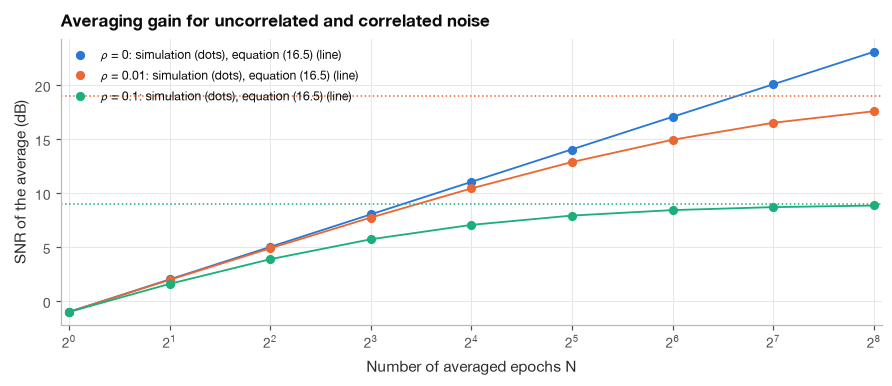

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, rho in enumerate((0.0, 0.01, 0.1)):
    part = sim[sim["rho"] == rho]
    ax.plot(part["N"], part["SNR theory (dB)"], color=C[k], lw=1.2)
    ax.plot(part["N"], part["SNR measured (dB)"], "o", color=C[k], ms=5,
            label=fr"$\rho$ = {rho:g}: simulation (dots), equation (16.5) (line)")
for rho, k in ((0.01, 1), (0.1, 2)):
    ax.axhline(10 * np.log10(P_s / (rho * sigma**2)), color=C[k], ls=":", lw=1)
ax.set_xscale("log", base=2)
ax.set(xlabel="Number of averaged epochs N", ylabel="SNR of the average (dB)",
       title="Averaging gain for uncorrelated and correlated noise")
ax.legend(loc="upper left", fontsize=8)
plt.show()

(sec-10-1-3)=
## 10.1.3 What Averaging Requires

The derivation leaned on [(10.1)](#eq-10-1) in its exact form, and every part of that equation is an assumption about the measurement. I find it useful to list them, because in practice averaging fails when one of them is quietly violated.

1. **Time-locking.** We must know where each repetition starts, to within a small fraction of the duration of the fastest feature in the waveform. For evoked potentials the stimulus computer provides an exact trigger. For the ECG there is no external trigger, so the beats must be found in the signal itself, usually by a QRS detector such as the Pan–Tompkins algorithm of Section 19.1, and the averaged waveform can only be as sharp as the detector's timing is precise. [Section 10.1.4](#sec-10-1-4) makes this quantitative.
2. **A repeatable signal.** The waveform $s[n]$ must be the same in every epoch. Normal sinus beats of one person over a few minutes come close, but the T wave changes with heart rate, the QRS amplitude changes with respiration, and an ectopic beat has a completely different shape. Averaging a mixture of beat types produces a waveform that matches none of them, which is why beats are usually classified first and only the dominant class is averaged ([Section 10.1.7](#sec-10-1-7)).
3. **Independent noise.** The noise in different epochs must be uncorrelated, and in particular it must not be time-locked to the events. Muscle noise and amplifier noise satisfy this well. Slow baseline wander, which changes little from one beat to the next, does not, and neither does power-line hum when the event rate is locked to the mains frequency.
4. **Stationary noise.** We assumed the same $\sigma^2$ in every epoch. When a few epochs are much noisier than the rest (a patient moving, an electrode being touched), they dominate the average. The plain mean then stops being the best combination, and weighted or robust averages do better.

(sec-10-1-4)=
## 10.1.4 Latency Jitter Acts as a Low-Pass Filter

Suppose the alignment is imperfect: the $i$-th epoch contains the waveform shifted by a random latency $\tau_i$ samples,

$$
x_i[n] = s[n - \tau_i] + v_i[n],
$$

where the $\tau_i$ are independent and drawn from a probability mass function $p[\tau] = \Pr(\tau_i = \tau)$. The noise still averages away as before, so we focus on the expected value of the average.

**Step 1: take the expectation over the random shifts.** The expected value of a function of a discrete random variable is the sum of the function's values weighted by their probabilities, so for each epoch

$$
\mathbb{E}\big[s[n - \tau_i]\big] = \sum_{\tau} p[\tau]\, s[n - \tau].
$$

**Step 2: average over epochs.** Every epoch has the same expected value, and the noise has zero mean, so

(eq-10-6)=
\begin{equation*}
\mathbb{E}\big[\bar{x}_N[n]\big] = \frac{1}{N}\sum_{i=1}^{N}\sum_{\tau} p[\tau]\, s[n - \tau] = \sum_{\tau} p[\tau]\, s[n - \tau] = (p * s)[n]. \tag{10.6}
\end{equation*}

The right-hand side is a convolution sum ([Section 4.2](../ch05_convolution/02_convolution_sum.ipynb)). The jittered average is the true waveform passed through a filter whose impulse response is the probability distribution of the jitter. A probability mass function is non-negative and sums to one, so this filter has unit gain at DC and is a smoothing filter, a weighted moving average.

**Step 3: move to the frequency domain.** Convolution becomes multiplication, so the spectrum of the expected average is $S(f)\,P(f)$, where $P(f)$ is the Fourier transform of the jitter distribution. For Gaussian jitter with standard deviation $\sigma_\tau$ seconds, the transform of the Gaussian density is again a Gaussian (Section 8.2):

(eq-10-7)=
\begin{equation*}
P(f) = e^{-2\pi^2\sigma_\tau^2 f^2}. \tag{10.7}
\end{equation*}

**Step 4: find the cutoff.** The power gain $|P(f)|^2 = e^{-4\pi^2\sigma_\tau^2 f^2}$ falls to one half where $4\pi^2\sigma_\tau^2 f^2 = \ln 2$, that is, at

(eq-10-8)=
\begin{equation*}
f_c = \frac{\sqrt{\ln 2}}{2\pi\,\sigma_\tau} \approx \frac{0.133}{\sigma_\tau}. \tag{10.8}
\end{equation*}

A jitter of 2 ms puts the $-3$ dB point at about 66 Hz, which barely touches the ECG. A jitter of 5 ms puts it at 27 Hz, inside the band where the QRS complex has much of its energy, so the averaged R wave comes out lower and wider than the true one. For the P300 component of the event-related potential, whose latency varies by tens of milliseconds from trial to trial, the effective cutoff is a few hertz.

We verify [(10.6)](#eq-10-6) by jittering the clean beats of record 100 with Gaussian shifts of standard deviation 2, 5 and 10 ms, averaging, and comparing each result with the template convolved with a sampled Gaussian kernel.

In [5]:
def jittered_average(x, peaks, sd_ms, pre, post):
    """Average epochs whose alignment points are shifted by Gaussian jitter of sd_ms."""
    shifts = np.round(rng.normal(0, sd_ms * fs / 1000, peaks.size)).astype(int)
    epochs, _ = beat_epochs(x, peaks + shifts, pre, post)
    return epochs.mean(axis=0)


def gaussian_kernel(sd_ms):
    """Sampled Gaussian probability mass function of the jitter (sums to one)."""
    sd = sd_ms * fs / 1000
    k = np.arange(-int(4 * sd) - 1, int(4 * sd) + 2)
    p = np.exp(-0.5 * (k / sd) ** 2)
    return p / p.sum()


jitter_results = {}
for sd_ms in (2, 5, 10):
    avg_j = jittered_average(ecg100, r100, sd_ms, pre, post)
    predicted = np.convolve(template, gaussian_kernel(sd_ms), mode="same")   # equation (16.6)
    core = slice(40, -40)                                                    # avoid convolution edges
    jitter_results[sd_ms] = (avg_j, predicted)
    print(f"sd = {sd_ms:2d} ms: R amplitude {avg_j[pre]:.3f} mV (true {template[pre]:.3f} mV), "
          f"RMS difference from (16.6) {np.sqrt(np.mean((avg_j - predicted)[core] ** 2)) * 1000:.1f} uV, "
          f"f_c = {np.sqrt(np.log(2)) / (2 * np.pi * sd_ms / 1000):.0f} Hz")

sd =  2 ms: R amplitude 1.159 mV (true 1.190 mV), RMS difference from (16.6) 2.1 uV, f_c = 66 Hz
sd =  5 ms: R amplitude 0.983 mV (true 1.190 mV), RMS difference from (16.6) 5.2 uV, f_c = 27 Hz
sd = 10 ms: R amplitude 0.671 mV (true 1.190 mV), RMS difference from (16.6) 4.8 uV, f_c = 13 Hz


The averages match the prediction of [(10.6)](#eq-10-6) to within a few microvolts, the residual being the finite-sample scatter of the shifts. The R wave loses a little amplitude at 2 ms and a substantial fraction at 10 ms, while the slow P and T waves are almost untouched, exactly as a low-pass filter would treat them.

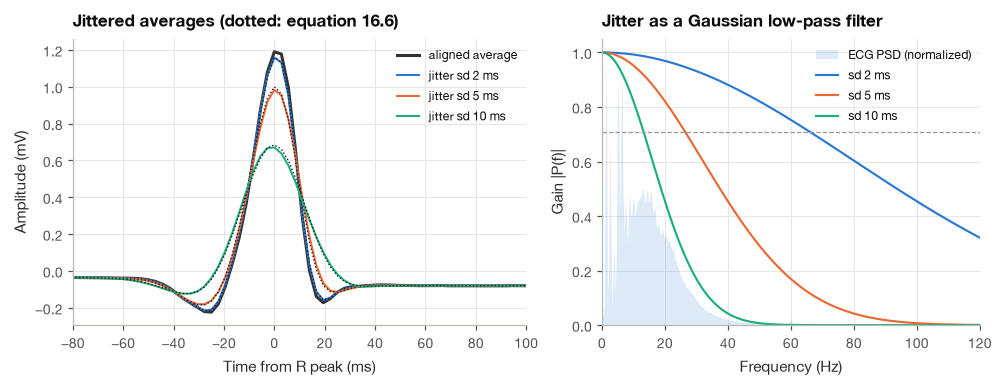

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ax.plot(t_ep, template, color="0.2", lw=2, label="aligned average")
for k, sd_ms in enumerate((2, 5, 10)):
    avg_j, predicted = jitter_results[sd_ms]
    ax.plot(t_ep, avg_j, color=C[k], lw=1.3, label=f"jitter sd {sd_ms} ms")
    ax.plot(t_ep, predicted, ":", color="0.1", lw=0.9)
ax.set(xlim=(-80, 100), xlabel="Time from R peak (ms)", ylabel="Amplitude (mV)",
       title="Jittered averages (dotted: equation 16.6)")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
f = np.linspace(0, 120, 400)
f_ecg, P_ecg = signal.welch(ecg100, fs, nperseg=1024)
ax.fill_between(f_ecg, 0, P_ecg / P_ecg.max(), color=C[0], alpha=0.15, lw=0, label="ECG PSD (normalized)")
for k, sd_ms in enumerate((2, 5, 10)):
    gain = np.exp(-2 * np.pi**2 * (sd_ms / 1000) ** 2 * f**2)        # equation (16.7)
    ax.plot(f, gain, color=C[k], label=f"sd {sd_ms} ms")
ax.axhline(1 / np.sqrt(2), color="0.6", lw=0.8, ls="--")
ax.set(xlim=(0, 120), ylim=(0, 1.05), xlabel="Frequency (Hz)", ylabel="Gain |P(f)|",
       title="Jitter as a Gaussian low-pass filter")
ax.legend(loc="upper right", fontsize=8)
plt.show()

The practical lesson is that alignment precision matters more as the waveform gets sharper. A QRS complex lasts about 80 to 100 ms but its upstroke takes only 10 to 20 ms, so a few milliseconds of jitter already matter. The remedy, used in the next subsection, is to refine the alignment by cross-correlating each epoch with the current average.

(sec-10-1-5)=
## 10.1.5 Averaging Real ECG Beats, Step by Step

Record 105 of the MIT-BIH Arrhythmia Database is a classic hard case: its documentation describes the dominant feature as high-grade noise and artifact. We use four minutes from 1140 to 1380 s, where the trace is at its worst, and the reference beat annotations of the database as triggers.

### Step 1: Load the record and look at it

In [7]:
t_start, t_stop = 1140, 1380
rec105 = wfdb.rdrecord("../data/mitdb/105", channels=[0], sampfrom=t_start * fs, sampto=t_stop * fs)
ecg105 = rec105.p_signal[:, 0]
ann105 = wfdb.rdann("../data/mitdb/105", "atr", sampfrom=t_start * fs, sampto=t_stop * fs)
symbols = np.array(ann105.symbol)
r105 = ann105.sample[symbols == "N"] - t_start * fs
t105 = t_start + np.arange(ecg105.size) / fs
print(f"Lead {rec105.sig_name[0]}, {ecg105.size / fs:.0f} s, {len(r105)} normal beats, "
      f"{np.sum(symbols == 'V')} ventricular beats")

Lead MLII, 240 s, 348 normal beats, 6 ventricular beats


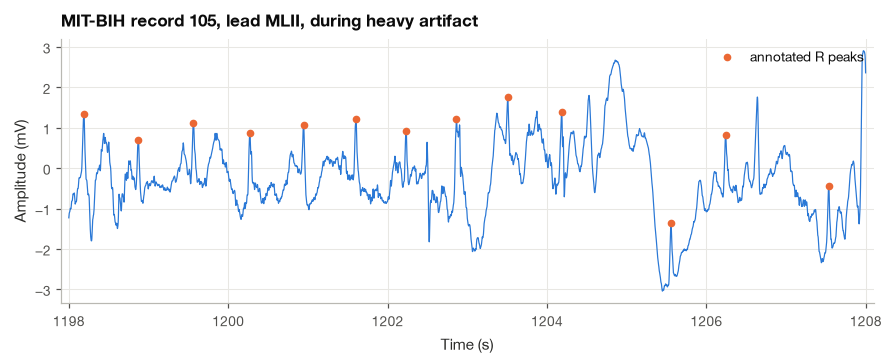

In [8]:
win = (t105 >= 1198) & (t105 < 1208)
r_win = r105[(t105[r105] >= 1198) & (t105[r105] < 1208)]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(t105[win], ecg105[win], color=C[0], lw=0.8)
ax.plot(t105[r_win], ecg105[r_win], "o", color=C[1], ms=4, label="annotated R peaks")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="MIT-BIH record 105, lead MLII, during heavy artifact")
ax.legend(loc="upper right")
plt.show()

Without the annotation markers, several of these beats would be impossible to find. The artifact here is several millivolts of slow, irregular motion artifact with fine high-frequency noise on top, larger than the QRS complexes themselves.

### Step 2: Remove baseline wander and cut the epochs

Averaging would eventually remove the slow drift as well, but slow noise is strongly correlated between neighboring beats, which by [(10.5)](#eq-10-5) makes averaging inefficient. A zero-phase 0.5 Hz high-pass ([Section 12.2](../ch18_ecg_preprocessing/index.md)) removes most of it cheaply and leaves the faster artifact to the averaging. We then cut 700 ms epochs around each normal beat, from 250 ms before the R peak to 450 ms after it, which covers the P wave, the QRS and the T wave at this heart rate.

In [9]:
x105 = signal.sosfiltfilt(hp_sos, ecg105)
epochs105, r105 = beat_epochs(x105, r105, pre, post)
rr = np.diff(r105) / fs
print(f"Epoch matrix: {epochs105.shape[0]} beats x {epochs105.shape[1]} samples")
print(f"Mean RR interval {rr.mean():.3f} s ({60 / rr.mean():.0f} bpm); shortest {rr.min():.3f} s")

Epoch matrix: 347 beats x 252 samples
Mean RR interval 0.690 s (87 bpm); shortest 0.592 s


The shortest RR interval is longer than the 700 ms epoch, so neighboring epochs never overlap.

### Step 3: Average and watch the noise shrink

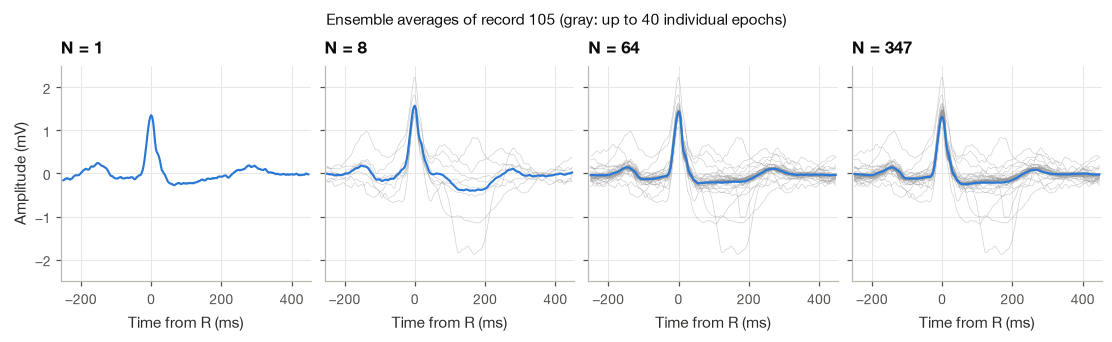

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(10, 3.0), sharey=True)
for ax, N in zip(axes, (1, 8, 64, len(epochs105))):
    for row in epochs105[:min(N, 40)]:
        ax.plot(t_ep, row, color="0.6", lw=0.4, alpha=0.5)
    ax.plot(t_ep, epochs105[:N].mean(axis=0), color=C[0], lw=1.4)
    ax.set(title=f"N = {N}", xlabel="Time from R (ms)", ylim=(-2.5, 2.5))
axes[0].set_ylabel("Amplitude (mV)")
fig.suptitle("Ensemble averages of record 105 (gray: up to 40 individual epochs)", fontsize=10)
plt.show()

A single epoch is unreadable. After 8 beats the QRS complex is recognizable, after 64 the T wave appears, and the average of all 347 beats shows a clean P–QRS–T complex.

### Step 4: Estimate the residual noise without a clean reference

How clean is the final average? In a real recording we do not know $s[n]$, so we cannot subtract it. A simple trick estimates the residual noise anyway: multiply every second epoch by $-1$ before averaging. The signal terms then cancel in pairs, $\frac{1}{N}\sum_i (-1)^i s[n] = 0$ for even $N$, while the noise terms, being independent with zero mean, have exactly the same variance $\sigma^2/N$ as in the ordinary average, since flipping the sign of a zero-mean random variable does not change its variance. This **plus–minus average** is therefore a sample of pure residual noise.

In [11]:
def plus_minus_average(epochs):
    """Average with alternating signs: the signal cancels, the residual noise remains."""
    n_even = 2 * (len(epochs) // 2)
    signs = np.where(np.arange(n_even) % 2 == 0, 1.0, -1.0)
    return (signs[:, None] * epochs[:n_even]).mean(axis=0)


sigma105 = np.std(epochs105 - epochs105.mean(axis=0))      # single-epoch noise level
rows = []
for N in (4, 16, 64, 256):
    pm = plus_minus_average(epochs105[:N])
    rows.append({"N": N, "plus-minus RMS (mV)": np.sqrt(np.mean(pm**2)),
                 "sigma / sqrt(N) (mV)": sigma105 / np.sqrt(N)})
print(f"Single-epoch noise RMS: {sigma105:.3f} mV")
print(pd.DataFrame(rows).to_string(index=False, float_format="%.4f"))

Single-epoch noise RMS: 0.499 mV
  N  plus-minus RMS (mV)  sigma / sqrt(N) (mV)
  4               0.1115                0.2493
 16               0.1053                0.1247
 64               0.0271                0.0623
256               0.0258                0.0312


The single-epoch noise is about half a millivolt, larger than the T wave. The residual noise measured by the plus–minus average follows the $\sigma/\sqrt{N}$ prediction within the scatter expected from one realization (each estimate is itself a noisy number, and the noise level varies along the record), and after 256 beats it is a few tens of microvolts.

### Step 5: Refine the alignment by cross-correlation

The database annotations were placed and checked by cardiologists and are already precise to within a sample or two. An automatic QRS detector running on a record this noisy would not be. To see what realignment can do, we perturb the annotated R peaks with Gaussian jitter of 6 ms standard deviation, a realistic error for a simple detector on noisy data, and then repair the alignment. The algorithm is the template matching of Section 6.2, applied iteratively:

1. Average the epochs with the current alignment to get a template.
2. For each epoch, find the shift within $\pm 15$ samples (about $\pm 42$ ms) that maximizes the correlation between the shifted epoch and the template.
3. Move the alignment point by that shift and repeat from step 1 until the shifts stop changing.

In [12]:
def realign(x, peaks, template, pre, post, max_lag=15):
    """Shift each alignment point to maximize its correlation with the template (Section 6.2)."""
    tpl = template - template.mean()
    lags = np.arange(-max_lag, max_lag + 1)
    best = np.empty(peaks.size, dtype=int)
    for i, k in enumerate(peaks):
        segment = x[k - pre - max_lag:k + post + max_lag]
        scores = [np.dot(segment[m:m + pre + post] - segment[m:m + pre + post].mean(), tpl)
                  for m in range(2 * max_lag + 1)]
        best[i] = lags[np.argmax(scores)]
    return peaks + best


inner = r105[(r105 > pre + 20) & (r105 < len(x105) - post - 20)]
triggers = inner + np.round(rng.normal(0, 6e-3 * fs, inner.size)).astype(int)
avg_true = beat_epochs(x105, inner, pre, post)[0].mean(axis=0)
avg_jit = beat_epochs(x105, triggers, pre, post)[0].mean(axis=0)

aligned = triggers.copy()
for iteration in range(4):
    tpl = beat_epochs(x105, aligned, pre, post)[0].mean(axis=0)
    new = realign(x105, aligned, tpl, pre, post)
    n_moved = np.sum(new != aligned)
    aligned = new
    print(f"iteration {iteration + 1}: {n_moved:3d} alignment points moved")
avg_re = beat_epochs(x105, aligned, pre, post)[0].mean(axis=0)

offset = np.median(aligned - inner)            # the template may settle with a constant offset
err_before = (triggers - inner) / fs * 1000
err_after = (aligned - offset - inner) / fs * 1000
print(f"Timing error RMS: {np.sqrt(np.mean(err_before**2)):.1f} ms before, "
      f"{np.sqrt(np.mean(err_after**2)):.1f} ms after realignment")
print(f"R amplitude: annotated {avg_true.max():.3f} mV, jittered {avg_jit.max():.3f} mV, "
      f"realigned {avg_re.max():.3f} mV")

iteration 1: 289 alignment points moved


iteration 2:  41 alignment points moved
iteration 3:   8 alignment points moved
iteration 4:   5 alignment points moved
Timing error RMS: 5.9 ms before, 11.9 ms after realignment
R amplitude: annotated 1.316 mV, jittered 1.155 mV, realigned 1.342 mV


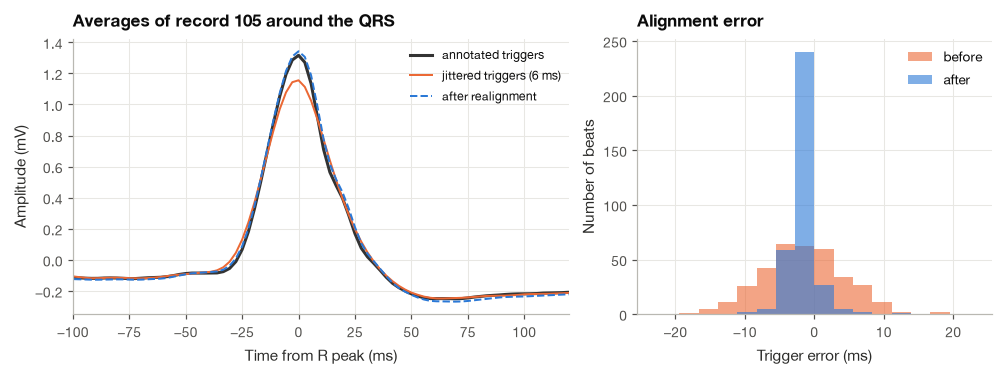

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
shift = int(offset)
ax.plot(t_ep, avg_true, color="0.2", lw=2, label="annotated triggers")
ax.plot(t_ep, avg_jit, color=C[1], lw=1.3, label="jittered triggers (6 ms)")
ax.plot(t_ep, np.roll(avg_re, shift), "--", color=C[0], lw=1.3, label="after realignment")
ax.set(xlim=(-100, 120), xlabel="Time from R peak (ms)", ylabel="Amplitude (mV)",
       title="Averages of record 105 around the QRS")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
bins = np.arange(-25, 26, 2.78)
ax.hist(err_before, bins=bins, color=C[1], alpha=0.6, label="before")
ax.hist(err_after, bins=bins, color=C[0], alpha=0.6, label="after")
ax.set(xlabel="Trigger error (ms)", ylabel="Number of beats", title="Alignment error")
ax.legend(loc="upper right")
plt.show()

Realignment brings almost every trigger back to within a sample of the annotated position, and the averaged QRS recovers its full amplitude. A handful of epochs, those hit by the largest artifacts, lock onto the wrong feature; their shifts land at the edge of the search range. In a production system I would reject such epochs, together with any whose correlation with the template stays low, before the final average.

(sec-10-1-6)=
## 10.1.6 Checking the $\sqrt{N}$ Law on Real Noise

In record 105 we could only estimate the residual noise. To test [(10.4)](#eq-10-4) exactly, we need a recording whose clean signal we know. We build one in the manner of a noise stress test {cite:p}`moody1984`: we take all 30 minutes of record 100, high-passed at 0.5 Hz, and add one of the three real noise recordings of the Noise Stress Test Database: muscle artifact (`ma`), electrode motion (`em`) and baseline wander (`bw`). Each noise is scaled so that the single-epoch SNR is 0 dB. Because we know which part of each epoch is noise, the residual in any average is exactly the average of the noise epochs.

The experiment is run in two ways. First, the $N$ beats are drawn at random from the 30 minutes, so that the noise in different epochs comes from times that are far apart and is, for practical purposes, independent. Second, the $N$ beats are consecutive, which is what a bedside monitor or a signal-averaged ECG system actually does.

In [14]:
rec_full = wfdb.rdrecord("../data/mitdb/100", channels=[0])
ecg_full = signal.sosfiltfilt(hp_sos, rec_full.p_signal[:, 0])
ann_full = wfdb.rdann("../data/mitdb/100", "atr")
r_full = ann_full.sample[np.array(ann_full.symbol) == "N"]
clean_epochs, r_full = beat_epochs(ecg_full, r_full, pre, post)
P_s_full = np.mean(clean_epochs.mean(axis=0) ** 2)
idx = r_full[:, None] + np.arange(-pre, post)

N_grid = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256])
gain_rows = []
for name in ("ma", "em", "bw"):
    v = wfdb.rdrecord(f"../data/nstdb/{name}", channels=[0]).p_signal[:, 0]
    V = v[idx] - v.mean()
    V *= np.sqrt(P_s_full / np.mean(V**2))                 # single-epoch SNR = 0 dB
    for N in N_grid:
        draws = np.array([V[rng.choice(len(V), N, replace=False)].mean(axis=0) for _ in range(300)])
        n_blocks = len(V) // N
        blocks = V[:n_blocks * N].reshape(n_blocks, N, -1).mean(axis=1)
        gain_rows.append({"noise": name, "N": N,
                          "random beats (dB)": 10 * np.log10(P_s_full / np.mean(draws**2)),
                          "consecutive beats (dB)": 10 * np.log10(P_s_full / np.mean(blocks**2))})
gains = pd.DataFrame(gain_rows)
print(f"{len(r_full)} normal beats; theory at N = 256: {10 * np.log10(256):.1f} dB")
print(gains[gains["N"].isin([4, 16, 256])].to_string(index=False, float_format="%.1f"))

2237 normal beats; theory at N = 256: 24.1 dB
noise   N  random beats (dB)  consecutive beats (dB)
   ma   4                6.2                     3.8
   ma  16               11.7                    14.0
   ma 256               24.3                    31.6
   em   4                6.1                     6.7
   em  16               12.1                    17.1
   em 256               24.4                    31.0
   bw   4                6.9                     2.6
   bw  16               11.7                    14.7
   bw 256               24.7                    40.1


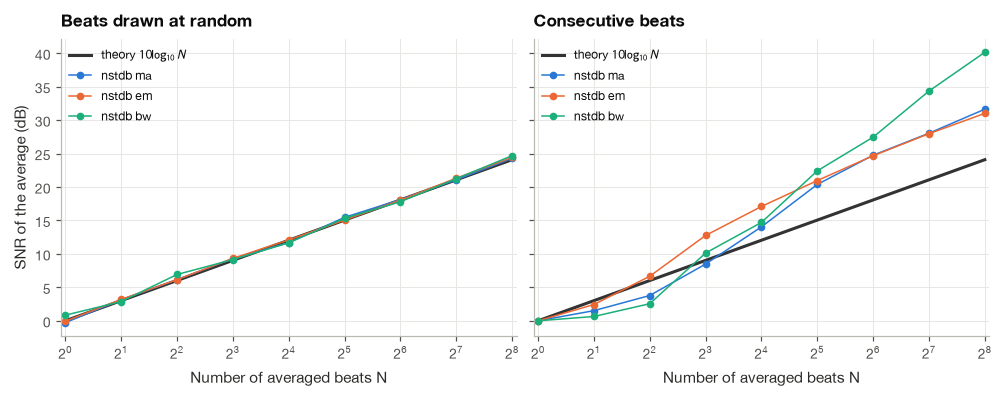

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, col, title in zip(axes, ("random beats (dB)", "consecutive beats (dB)"),
                          ("Beats drawn at random", "Consecutive beats")):
    ax.plot(N_grid, 10 * np.log10(N_grid), color="0.2", lw=2, label=r"theory $10\log_{10}N$")
    for k, name in enumerate(("ma", "em", "bw")):
        part = gains[gains["noise"] == name]
        ax.plot(part["N"], part[col], "o-", color=C[k], ms=4, lw=1, label=f"nstdb {name}")
    ax.set_xscale("log", base=2)
    ax.set(xlabel="Number of averaged beats N", title=title)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("SNR of the average (dB)")
plt.show()

With randomly drawn beats all three noise types follow the theoretical line almost exactly, even though none of them is Gaussian or stationary. The $\sqrt{N}$ law needs only zero mean and lack of correlation between epochs, and random sampling across half an hour supplies both.

Consecutive beats behave differently, and the reason is correlation. Baseline wander and much of the electrode-motion and muscle records consist of slow components that change little over one RR interval, so two neighboring epochs share part of their noise ($\rho > 0$ in [(10.5)](#eq-10-5)) and averaging a handful of consecutive beats gains much less than 3 dB per doubling. For larger $N$ the curves overtake the theory. Baseline wander follows respiration up and down, so beats a few seconds apart catch the baseline at opposite phases of a breath, and their noise is negatively correlated; a negative $\rho$ makes the bracket in [(10.5)](#eq-10-5) smaller than one and the average better than independent noise would allow. This is why practical systems remove the slow noise with a high-pass filter before averaging, as we did in Step 2 for record 105, and leave the averaging to deal with the faster noise that varies from beat to beat.

(sec-10-1-7)=
## 10.1.7 Median Averaging When Ectopic Beats Are Present

Record 119 contains long runs of ventricular bigeminy and trigeminy: premature ventricular beats alternate with normal beats. If we average every detected QRS complex, as an automatic system that does not classify beats would do, the average is a blend of two very different waveforms. The sample-by-sample **median** of the epochs is a simple defense. At each latency $n$ it takes the middle value of $x_1[n], \ldots, x_N[n]$, so as long as fewer than half of the epochs are outliers, the median stays within the spread of the majority. It is the ensemble counterpart of the median filter of [Section 13.3](../ch13_filter_fundamentals/index.md): the median filter works along time, the median average works across epochs.

We take six minutes of record 119 (1080 to 1440 s), in which roughly a third of the beats are ventricular, and compare three templates: the mean of all beats, the median of all beats, and the mean of the normal beats only, which serves as the reference.

In [16]:
t0_119, t1_119 = 1080, 1440
rec119 = wfdb.rdrecord("../data/mitdb/119", channels=[0], sampfrom=t0_119 * fs, sampto=t1_119 * fs)
x119 = signal.sosfiltfilt(hp_sos, rec119.p_signal[:, 0])
ann119 = wfdb.rdann("../data/mitdb/119", "atr", sampfrom=t0_119 * fs, sampto=t1_119 * fs)
sym119 = np.array(ann119.symbol)
is_beat = np.isin(sym119, ["N", "V"])
peaks119 = ann119.sample[is_beat] - t0_119 * fs
labels119 = sym119[is_beat]
keep = (peaks119 - pre >= 0) & (peaks119 + post <= x119.size)
peaks119, labels119 = peaks119[keep], labels119[keep]
epochs119, _ = beat_epochs(x119, peaks119, pre, post)

mean_all = epochs119.mean(axis=0)
median_all = np.median(epochs119, axis=0)
mean_normal = epochs119[labels119 == "N"].mean(axis=0)
frac_v = np.mean(labels119 == "V")
print(f"{len(peaks119)} beats, {frac_v:.0%} ventricular")
for name, est in (("mean of all beats", mean_all), ("median of all beats", median_all)):
    rmse = np.sqrt(np.mean((est - mean_normal) ** 2))
    print(f"{name:20s}: RMS difference from the normal-beat template {rmse * 1000:5.0f} uV")

400 beats, 32% ventricular
mean of all beats   : RMS difference from the normal-beat template   276 uV
median of all beats : RMS difference from the normal-beat template    46 uV


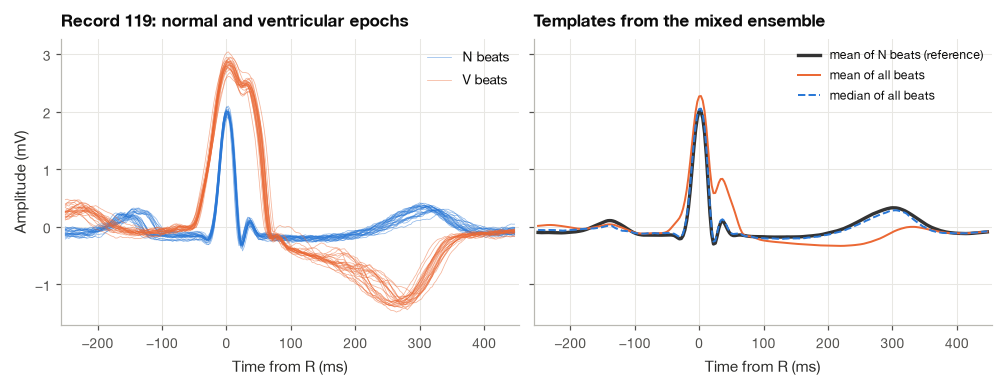

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
ax = axes[0]
for lab, col in (("N", C[0]), ("V", C[1])):
    sel = np.flatnonzero(labels119 == lab)[:25]
    for k, i in enumerate(sel):
        ax.plot(t_ep, epochs119[i], color=col, lw=0.5, alpha=0.5, label=f"{lab} beats" if k == 0 else None)
ax.set(xlabel="Time from R (ms)", ylabel="Amplitude (mV)", title="Record 119: normal and ventricular epochs")
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(t_ep, mean_normal, color="0.2", lw=2.2, label="mean of N beats (reference)")
ax.plot(t_ep, mean_all, color=C[1], lw=1.3, label="mean of all beats")
ax.plot(t_ep, median_all, "--", color=C[0], lw=1.3, label="median of all beats")
ax.set(xlabel="Time from R (ms)", title="Templates from the mixed ensemble")
ax.legend(loc="upper right", fontsize=8)
plt.show()

The ventricular beats are wide, tall and followed by an inverted T wave, and the mean of all beats inherits about a third of that shape: a widened QRS and a T wave that is too shallow. The median follows the normal-beat template closely. It is not perfect: where the two beat types differ, the median is pulled slightly towards the minority, because with a fraction $\varepsilon$ of outliers on one side it picks out roughly the $\frac{1}{2(1-\varepsilon)}$ quantile of the majority instead of its middle. That bias grows with the noise spread and with $\varepsilon$, and once the ventricular beats reach half of the ensemble, as in a long run of pure bigeminy, the median breaks down as well.

### The price of the median

Robustness to outliers is not free. For Gaussian noise and large $N$, a standard result from the theory of order statistics says that the sample median is approximately Gaussian with variance $1/\big(4N f_v(0)^2\big)$, where $f_v(0) = 1/(\sigma\sqrt{2\pi})$ is the noise density at its center. Substituting,

(eq-10-9)=
\begin{equation*}
\operatorname{Var}\big(\operatorname{median}\big) \approx \frac{2\pi\sigma^2}{4N} = \frac{\pi}{2}\cdot\frac{\sigma^2}{N}. \tag{10.9}
\end{equation*}

Compared with [(10.3)](#eq-10-3), the median leaves $\pi/2 \approx 1.57$ times more noise power, a loss of $10\log_{10}(\pi/2) \approx 2$ dB; equivalently, it needs about 57% more beats to reach the same residual noise as the mean. For heavy-tailed noise such as motion artifact, where a few epochs carry huge excursions, the comparison can reverse and the median becomes the more accurate estimator. A trimmed mean, which discards a fixed fraction of the largest and smallest values at each latency before averaging, sits between the two.

In [18]:
N_med, sigma_med = 64, 0.1
draws = rng.normal(0, sigma_med, (20000, N_med))
var_mean = np.var(draws.mean(axis=1))
var_median = np.var(np.median(draws, axis=1))
print(f"Variance ratio median/mean (simulation): {var_median / var_mean:.3f}")
print(f"pi/2 from equation (16.9)              : {np.pi / 2:.3f}")

Variance ratio median/mean (simulation): 1.521
pi/2 from equation (16.9)              : 1.571


In practice I treat the median template as a safety net and prefer to classify the beats first, as in Section 19.3, and then take the ordinary mean of the dominant class. With good classification the mean keeps its 2 dB advantage, and the median protects against the beats the classifier gets wrong.

(sec-10-1-8)=
## 10.1.8 Averaging Event-Related Potentials

The second classical use of averaging is the **event-related potential** (ERP), the brain's response to a stimulus, which is the subject of [Section 13.3](../ch20_eeg/index.md). In the oddball paradigm, for example, a subject hears frequent standard tones and occasional target tones, and the targets evoke the P300, a positive deflection peaking around 300 ms after the stimulus over parietal sites with an amplitude of the order of 5 to 15 µV. The ongoing EEG on which it rides has an RMS amplitude of tens of microvolts, so the ERP is invisible in single trials and typically tens of trials per condition are averaged {cite:p}`luck2014`.

To work with a known ground truth, I simulate the ERP but keep the background real. The background is the Pz channel of subject S001 from the EEG Motor Movement/Imagery Dataset {cite:p}`schalk2004,goldberger2000`, two one-minute baseline runs (eyes open and eyes closed), band-passed from 0.1 to 30 Hz as is common for ERP work. Onto this background we add an ERP made of a small negative wave at 100 ms ($-3$ µV) and a P300-like positive wave at 320 ms ($8$ µV), at stimulus times separated by a random interval of 1.0 to 1.4 s. In a second version the P300 latency varies from trial to trial with a standard deviation of 40 ms, which is realistic for a component that depends on how quickly each stimulus is evaluated.

In [19]:
fs_eeg = 160.0
background = []
for run in ("S001R01", "S001R02"):
    raw = mne.io.read_raw_edf(f"../data/eegmmidb/{run}.edf", preload=True)
    mne.datasets.eegbci.standardize(raw)
    raw.set_montage("standard_1005")
    pz = raw.get_data(picks=["Pz"])[0] * 1e6                           # V -> uV
    background.append(signal.sosfiltfilt(
        signal.butter(2, [0.1, 30], "band", fs=fs_eeg, output="sos"), pz))
eeg_bg = np.concatenate(background)

t_erp = np.arange(int(-0.2 * fs_eeg), int(0.8 * fs_eeg)) / fs_eeg      # -200 to 800 ms


def erp_waveform(t, p300_latency=0.32):
    """N1-like and P300-like Gaussian waves (uV) at the given P300 latency (s)."""
    return (-3 * np.exp(-0.5 * ((t - 0.10) / 0.025) ** 2)
            + 8 * np.exp(-0.5 * ((t - p300_latency) / 0.07) ** 2))


onsets = np.cumsum(rng.uniform(1.0, 1.4, 200))
onsets = (onsets[(onsets > 0.3) & (onsets < eeg_bg.size / fs_eeg - 1.0)] * fs_eeg).astype(int)
n_ep = len(onsets)
epoch_idx = onsets[:, None] + np.round(t_erp * fs_eeg).astype(int)

trials = {}
for label, jitter_sd in (("fixed latency", 0.0), ("jittered P300", 0.04)):
    latencies = 0.32 + rng.normal(0, jitter_sd, n_ep)
    ep = eeg_bg[epoch_idx] + np.array([erp_waveform(t_erp, lat) for lat in latencies])
    ep -= ep[:, t_erp < 0].mean(axis=1, keepdims=True)                # baseline correction
    trials[label] = ep

erp_true = erp_waveform(t_erp)
bg_rms = np.std(eeg_bg[epoch_idx])
print(f"{n_ep} trials; background EEG RMS {bg_rms:.1f} uV; P300 peak {erp_true.max():.1f} uV")
print(f"Single-trial SNR over the epoch: {10 * np.log10(np.mean(erp_true**2) / bg_rms**2):.1f} dB")

100 trials; background EEG RMS 52.7 uV; P300 peak 8.0 uV
Single-trial SNR over the epoch: -25.2 dB


The single-trial SNR is around $-20$ dB, so by [(10.4)](#eq-10-4) we need on the order of a hundred trials to bring the ERP up to the noise level of the average and many more for a clean waveform. The figure shows the running average for 10, 30 and all trials, and, for the jittered version, the prediction of [(10.6)](#eq-10-6): the true ERP convolved with the Gaussian latency distribution. Because only the P300 is jittered, we convolve only the P300 part.

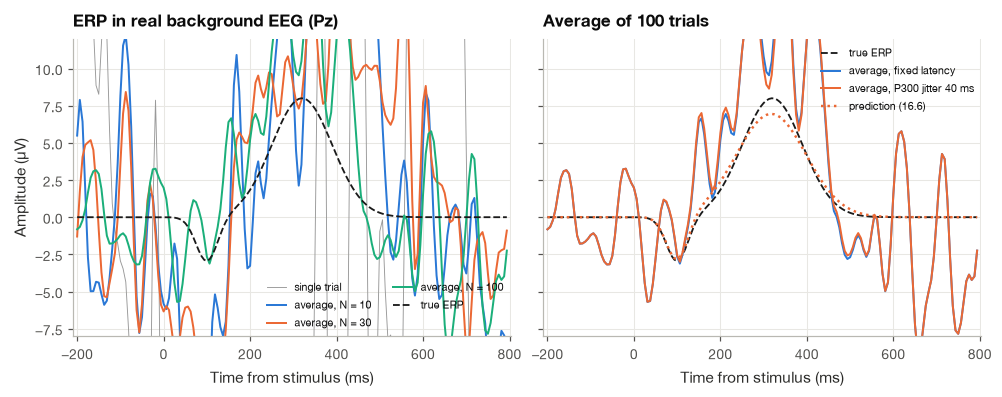

P300 peak of the average: 20.8 uV (fixed), 19.9 uV (jittered), predicted 6.9 uV, true 8.0 uV


In [20]:
sd = 0.04 * fs_eeg
kernel = np.exp(-0.5 * (np.arange(-4 * sd, 4 * sd + 1) / sd) ** 2)
kernel /= kernel.sum()
n1_part = -3 * np.exp(-0.5 * ((t_erp - 0.10) / 0.025) ** 2)
p300_smeared = np.convolve(erp_true - n1_part, kernel, mode="same")   # equation (16.6), P300 only
predicted_jit = n1_part + p300_smeared

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
ax = axes[0]
ax.plot(t_erp * 1000, trials["fixed latency"][0], color="0.6", lw=0.6, label="single trial")
for k, N in enumerate((10, 30, n_ep)):
    ax.plot(t_erp * 1000, trials["fixed latency"][:N].mean(axis=0), color=C[k], lw=1.3, label=f"average, N = {N}")
ax.plot(t_erp * 1000, erp_true, "--", color="0.1", lw=1.2, label="true ERP")
ax.set(xlabel="Time from stimulus (ms)", ylabel="Amplitude (µV)", ylim=(-30, 30),
       title="ERP in real background EEG (Pz)")
ax.legend(loc="lower right", fontsize=7, ncols=2)

ax = axes[1]
ax.plot(t_erp * 1000, erp_true, "--", color="0.1", lw=1.2, label="true ERP")
ax.plot(t_erp * 1000, trials["fixed latency"].mean(axis=0), color=C[0], lw=1.3, label="average, fixed latency")
ax.plot(t_erp * 1000, trials["jittered P300"].mean(axis=0), color=C[1], lw=1.3, label="average, P300 jitter 40 ms")
ax.plot(t_erp * 1000, predicted_jit, ":", color=C[1], lw=1.6, label="prediction (16.6)")
ax.set(xlabel="Time from stimulus (ms)", ylim=(-8, 12), title=f"Average of {n_ep} trials")
ax.legend(loc="upper right", fontsize=7)
plt.show()

p_fixed = trials["fixed latency"].mean(axis=0)[(t_erp > 0.2) & (t_erp < 0.45)].max()
p_jit = trials["jittered P300"].mean(axis=0)[(t_erp > 0.2) & (t_erp < 0.45)].max()
print(f"P300 peak of the average: {p_fixed:.1f} uV (fixed), {p_jit:.1f} uV (jittered), "
      f"predicted {predicted_jit.max():.1f} uV, true {erp_true.max():.1f} uV")

With ten trials the average still looks like EEG. With all trials the N1 and the P300 emerge and track the true waveform to within the residual noise, which by [(10.3)](#eq-10-3) has fallen to roughly a tenth of the background RMS. The jittered average shows the second lesson of this section in a new setting: its P300 is lower and broader than the true one, by the amount [(10.6)](#eq-10-6) predicts, even though every single trial contained a full-sized P300. A smaller averaged P300 can therefore mean either a smaller response or a more variable latency, and the average alone cannot tell them apart. This ambiguity is a well-known pitfall in clinical ERP studies, and it motivates single-trial methods and latency-corrected averaging, which is the realignment of Step 5 applied to brain responses.

## Summary

Ensemble averaging stacks epochs that are time-locked to a repeating event and averages them sample by sample. Under the model $x_i[n] = s[n] + v_i[n]$ with zero-mean noise that is uncorrelated across epochs, the average is unbiased and its noise variance falls as $\sigma^2/N$, so the SNR grows by a factor $N$ (3 dB per doubling) and the noise amplitude by $\sqrt{N}$. Correlation between epochs leaves a floor of $\rho\sigma^2$ that no amount of averaging removes, and random jitter in the alignment turns the expected average into the true waveform convolved with the jitter distribution, a low-pass filter whose cutoff $f_c \approx 0.133/\sigma_\tau$ falls inside the QRS band once the jitter reaches a few milliseconds. On real data the law held almost exactly for randomly drawn beats, failed in instructive ways for consecutive beats with slow noise, recovered a clean beat from record 105, and, with cross-correlation realignment, repaired a jittered trigger. The median average resisted ectopic beats in record 119 at a cost of about 2 dB for Gaussian noise, and averaging pulled a 8 µV P300 out of real EEG.

Averaging needs repetition. When the signal does not repeat, or when we cannot wait for hundreds of beats, we must separate signal and noise by their spectra instead. [Section 10.2](02_wiener_filter.ipynb) derives the optimal linear filter for that task, and it uses an averaged beat template to estimate the ECG spectrum. Averaged beat templates return in Section 19.3, and in Section 25.1 the beat matrix becomes the input to principal component analysis.

## Exercises

1. Show that a weighted average $\sum_i a_i x_i[n]$ with $\sum_i a_i = 1$ is unbiased under [(10.1)](#eq-10-1), and find its noise variance when epoch $i$ has noise variance $\sigma_i^2$. Use a Lagrange multiplier to show that the weights minimizing the variance are $a_i \propto 1/\sigma_i^2$. What does this suggest for record 105?
2. Using [(10.5)](#eq-10-5), find how many epochs are needed to come within 1 dB of the floor $\rho\sigma^2$ when $\rho = 0.05$. Then compute the SNR gain of averaging 64 epochs when the correlation exists only between neighbors, $\mathbb{E}[v_iv_{i+1}] = \rho\sigma^2$, and all other pairs are uncorrelated.
3. Derive the jitter filter for a latency that is uniformly distributed on $[-\Delta, \Delta]$ seconds. Show that $P(f) = \sin(2\pi f\Delta)/(2\pi f\Delta)$, find the frequency of its first zero for $\Delta = 5$ ms, and verify your result with the code of Section 10.1.4.
4. Repeat the experiment of [Section 10.1.6](#sec-10-1-6) with the noisy signal high-passed at 0.5 Hz before averaging, as in Step 2 of Section 10.1.5. How do the curves for consecutive beats change, and why?
5. In [Section 10.1.7](#sec-10-1-7), vary the window in record 119 so that the fraction of ventricular beats ranges from about 10% to 50% (use the rhythm annotations in `aux_note` to find stretches of bigeminy). Plot the RMS difference between the median template and the normal-beat template as a function of that fraction, and add a 20% trimmed mean for comparison.
6. Implement latency-corrected ERP averaging: estimate each trial's P300 latency by cross-correlating the trial (low-passed at 8 Hz) with the current average in a window of 200 to 500 ms, realign the trials, and re-average. Apply it to the jittered trials of Section 10.1.8. How much of the P300 amplitude do you recover, and how does the method behave if you rerun it with fewer trials?

## Further Reading

{cite:t}`luck2014` is the standard practical guide to ERP averaging, with careful discussions of latency jitter, baseline correction and the number of trials needed. {cite:t}`sornmo2005` (Chapter 3) develops ensemble averaging for evoked potentials and ECG beats, including weighted and robust averages and the effect of jitter, and {cite:t}`rangayyan2015` treats synchronized averaging as the first of the noise-removal methods for biomedical signals. The noise recordings used here are described by {cite:t}`moody1984`.